# Annual hypothesis tests


## Libraries and data


In [1]:
from pathlib import Path
import hashlib
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'PROJECT_HANDOFF.txt').is_file())
sys.path.insert(0, str(ROOT))
import sitecustomize

# The same notebook also works in the smaller portable project.
if (ROOT / 'portable_manifest.json').is_file():
    from portable_support import activate
    activate(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import pymannkendall as mk
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
from tools.scientific_plot_style import BLUE, RED, apply_scientific_style

SOURCE = ROOT / ('outputs/analysis_runs/19800101_20250101/'
                 '04_events_b367307a49b34165/overviews/0018a6e0978f17fc/'
                 'tables/annual.parquet')
SOURCE_SHA256 = 'bce3456a6919ab87c6aba1aba28472fe6942a74a450a74b96706441ee2e050e2'
if hashlib.sha256(SOURCE.read_bytes()).hexdigest() != SOURCE_SHA256:
    raise ValueError('Annual observations differ from the verified 04 table.')

annual = pd.read_parquet(SOURCE)
annual = annual.loc[annual.year.between(1981, 2024)].sort_values('year').copy()
assert np.array_equal(annual.year, np.arange(1981, 2025))
assert annual.complete_period.all()
assert np.isfinite(annual[['total_precip_mm', 'complete_events']]).all().all()

years = annual.year.to_numpy()
early = annual.loc[annual.year <= 2002, 'total_precip_mm'].to_numpy()
late = annual.loc[annual.year >= 2003, 'total_precip_mm'].to_numpy()
counts = annual.complete_events.to_numpy()
assert len(early) == len(late) == 22

FAMILY_ALPHA = 0.05
TEST_ALPHA = FAMILY_ALPHA / 2
CONFIDENCE = 1 - TEST_ALPHA  # 97.5% intervals for the two-test family
DIAGNOSTIC_LAG = 3

## Hypotheses and methods


In [2]:
# Two primary tests and effect sizes, directly from library implementations.
welch = stats.ttest_ind(late, early, equal_var=False, alternative='two-sided')
rain_ci = welch.confidence_interval(confidence_level=CONFIDENCE)
trend = mk.original_test(counts, alpha=TEST_ALPHA)
sen = stats.theilslopes(counts, years, alpha=CONFIDENCE, method='separate')
reject, adjusted_p, _, _ = multipletests(
    [welch.pvalue, trend.p], alpha=FAMILY_ALPHA, method='bonferroni')

difference = late.mean() - early.mean()
percent_change = 100 * difference / early.mean()
slope_decade = 10 * sen.slope
slope_ci = (10 * sen.low_slope, 10 * sen.high_slope)

results = pd.DataFrame([
    {'hypothesis': 'Precipitation', 'test': 'Welch t', 'n': '22 + 22',
     'H0': 'Later minus earlier mean = 0', 'H1': 'Mean difference != 0',
     'statistic_name': 't', 'statistic': float(welch.statistic),
     'df': float(welch.df), 'p': float(welch.pvalue),
     'effect': float(difference), 'CI_low': float(rain_ci.low),
     'CI_high': float(rain_ci.high), 'units': 'mm/year'},
    {'hypothesis': 'AR frequency', 'test': 'Mann–Kendall', 'n': '44',
     'H0': 'No monotonic trend', 'H1': 'Positive or negative monotonic trend',
     'statistic_name': 'Z', 'statistic': float(trend.z),
     'df': np.nan, 'p': float(trend.p),
     'effect': float(slope_decade), 'CI_low': float(slope_ci[0]),
     'CI_high': float(slope_ci[1]), 'units': 'events/year per decade'},
]).set_index('hypothesis')
results['p_bonferroni'] = adjusted_p
results['alpha_family'] = FAMILY_ALPHA
results['alpha_test'] = TEST_ALPHA
results['CI_level'] = CONFIDENCE
results['decision'] = np.where(reject, 'Reject H₀', 'Do not reject H₀')

# Diagnostics remain available as a DataFrame; the concise assessment is below.
diagnostic_samples = {
    'Precipitation 1981–2002': early,
    'Precipitation 2003–2024': late,
    'AR counts': counts,
    'AR counts after Sen detrending': counts - (sen.intercept + sen.slope * years),
}
diagnostic_rows = []
for name, sample in diagnostic_samples.items():
    lb = acorr_ljungbox(sample, lags=[DIAGNOSTIC_LAG], return_df=True).iloc[0]
    sw = stats.shapiro(sample) if name.startswith('Precipitation') else None
    diagnostic_rows.append({
        'sample': name, 'n': len(sample),
        'Shapiro_W': sw.statistic if sw is not None else np.nan,
        'Shapiro_p': sw.pvalue if sw is not None else np.nan,
        'Ljung_Box_Q': lb.lb_stat, 'Ljung_Box_p': lb.lb_pvalue,
    })
diagnostics = pd.DataFrame(diagnostic_rows).set_index('sample')

## Results


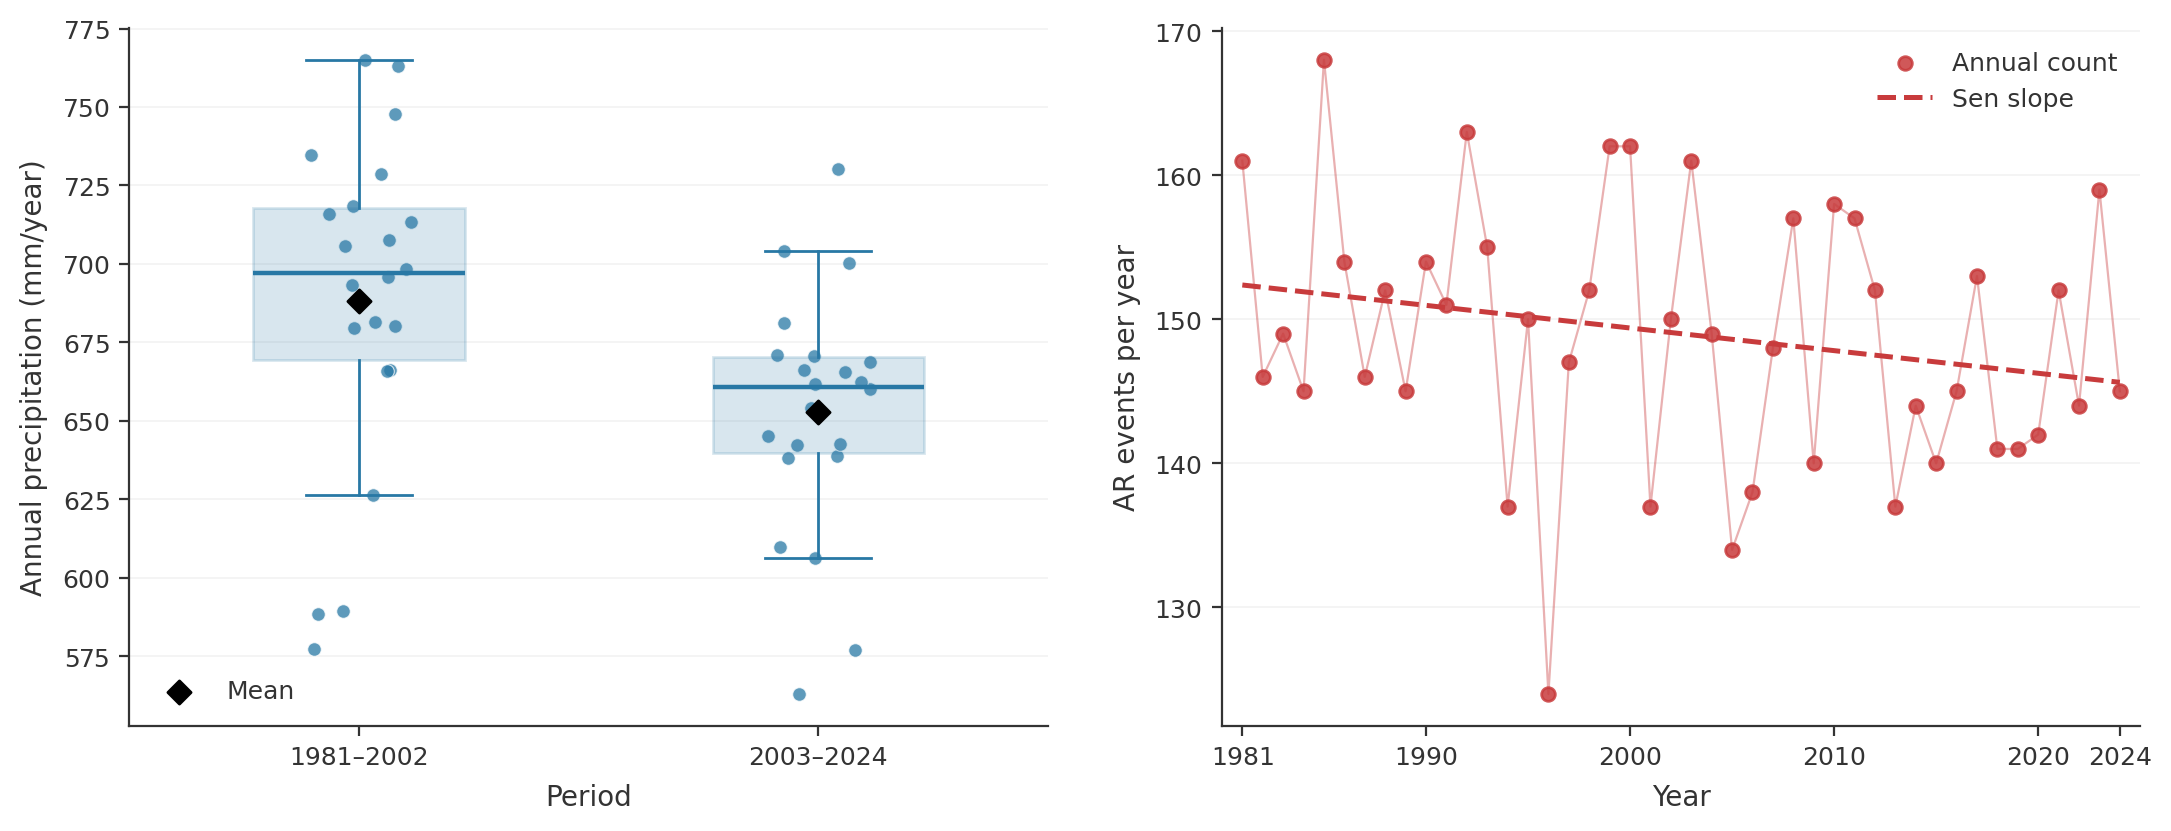

In [3]:
apply_scientific_style()
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.1), layout='constrained')

# Full ROI precipitation: each dot is one year, diamonds are sample means.
ax = axes[0]
ax.boxplot([early, late], positions=[0, 1], widths=.46, showfliers=False,
           patch_artist=True, tick_labels=['1981–2002', '2003–2024'],
           boxprops={'facecolor': BLUE, 'edgecolor': BLUE, 'alpha': .18},
           medianprops={'color': BLUE, 'linewidth': 1.6},
           whiskerprops={'color': BLUE}, capprops={'color': BLUE})
rng = np.random.default_rng(42)  # Horizontal display jitter only.
for i, sample in enumerate([early, late]):
    ax.scatter(i + rng.uniform(-.12, .12, len(sample)), sample,
               s=24, color=BLUE, alpha=.75, edgecolor='white', linewidth=.4)
ax.scatter([0, 1], [early.mean(), late.mean()], marker='D', s=35,
           color='black', zorder=4, label='Mean')
ax.set(xlabel='Period', ylabel='Annual precipitation (mm/year)')
ax.legend(loc='lower left')

# Full ROI event counts and the robust descriptive trend estimate.
ax = axes[1]
ax.plot(years, counts, color=RED, linewidth=.8, alpha=.4)
ax.scatter(years, counts, s=24, color=RED, alpha=.85, label='Annual count')
ax.plot(years, sen.intercept + sen.slope * years, color=RED,
        linestyle='--', linewidth=1.8, label='Sen slope')
ax.set(xlabel='Year', ylabel='AR events per year', xlim=(1980, 2025))
ax.set_xticks([1981, 1990, 2000, 2010, 2020, 2024])
ax.legend(loc='upper right')

for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=.18)
plt.show()

In [4]:
table = results[['test', 'n']].rename(columns={'test': 'Test', 'n': 'n'}).copy()
table['Effect [97.5% CI]'] = [
    f'{r.effect:+.2f} [{r.CI_low:+.2f}, {r.CI_high:+.2f}] {r.units}'
    for r in results.itertuples()]
table['Statistic'] = [f't = {welch.statistic:.3f} (df = {welch.df:.2f})',
                      f'Z = {trend.z:.3f}; S = {trend.s:.0f}']
table['p'] = results.p
table['p (Bonferroni)'] = results.p_bonferroni
table['Decision'] = results.decision
table.index.name = None
display(table.style.format({'p': '{:.4f}', 'p (Bonferroni)': '{:.4f}'}))

,Test,n,Effect [97.5% CI],Statistic,p,p (Bonferroni),Decision
Precipitation,Welch t,22 + 22,"-35.62 [-68.31, -2.94] mm/year",t = -2.542 (df = 38.50),0.0152,0.0303,Reject H₀
AR frequency,Mann–Kendall,44,"-1.57 [-4.00, +1.35] events/year per decade",Z = -1.357; S = -135,0.1746,0.3493,Do not reject H₀
